# Digital Image Processing Lab — Lab Task 04
## Geometric Transformations with Custom Inputs

| | |
|---|---|
| **Name** | Ubaidullah |
| **Roll No** | 2024-SE-17 |
| **Session / Semester** | 2024-28 (SE) / Fifth |
| **Instructor** | Engr. Fahad Nisar |
| **University / Department** | The University of Azad Jammu and Kashmir — Department of Software Engineering |

**Objective:** build one reusable `transform(image, operation, **params)` function that accepts custom values, validates every input, and performs scaling, cropping, flipping, translation and rotation correctly.

**Notebook map:** 1 Setup → 2 Load & validate image → 3 The `transform` function → 4 Prompts for custom input → 5 Demonstrations → 6 Interpolation comparison → 7 Rejected inputs → 8 Identity / correctness checks → 9 Observations → 10 Saved outputs.

## 1. Setup and declared limits

In [1]:
import os, math, json, hashlib, textwrap, platform
import numpy as np
import cv2 as cv
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

IMAGE_PATH = "input_image.png"            # input photo (read once, kept unchanged)
OUTPUT_DIR = "output_images"              # every transformed result is saved here
FIG_DIR    = os.path.join(OUTPUT_DIR, "comparisons")   # labelled original-vs-result figures
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Declared (and enforced inside transform) maximum output size
MAX_DIM    = 8000          # width or height of any output may not exceed this many pixels
MAX_PIXELS = 25_000_000    # width * height of any output may not exceed this

plt.rcParams.update({"figure.dpi": 100, "font.size": 9})

# Everything shown below is also collected here so the written report uses the very same numbers.
REPORT = {
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "opencv": cv.__version__, "matplotlib": matplotlib.__version__},
    "limits": {"MAX_DIM": MAX_DIM, "MAX_PIXELS": MAX_PIXELS},
}

def show_table(headers, rows):
    """Render a list of rows as a Markdown table inside the notebook."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    for r in rows:
        lines.append("| " + " | ".join(str(c).replace("|", "\\|").replace("\n", " ") for c in r) + " |")
    display(Markdown("\n".join(lines)))

print("Python", REPORT["versions"]["python"], "| NumPy", np.__version__,
      "| OpenCV", cv.__version__, "| Matplotlib", matplotlib.__version__)
print(f"Output limits: each side <= {MAX_DIM} px and <= {MAX_PIXELS:,} pixels in total")

Python 3.12.3 | NumPy 2.5.4 | OpenCV 5.0.0 | Matplotlib 3.11.2
Output limits: each side <= 8000 px and <= 25,000,000 pixels in total


## 2. Load the image and validate it
`load_image` checks that the file **exists**, **decodes** successfully and has **non-zero dimensions**.
Colour handling is consistent everywhere: OpenCV reads **BGR**, so the image is converted to **RGB once** at load time; every display uses RGB and every save converts RGB → BGR again.
The original array is made **read-only** and fingerprinted (SHA-256) so we can prove at the end that it was never modified.

File           : input_image.png
Width x Height : 600 x 400 pixels
Array shape    : (400, 600, 3)   (rows=height, columns=width, channels)
dtype          : uint8   | colour order: RGB   | writeable: False


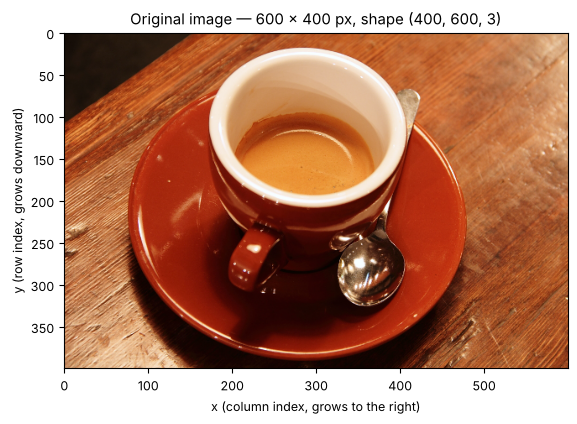

In [2]:
class TransformError(ValueError):
    """Raised for any invalid image, operation name or parameter value."""

def load_image(path):
    if not isinstance(path, (str, os.PathLike)):
        raise TransformError(f"Image path must be a string, got {type(path).__name__}.")
    if not os.path.isfile(path):
        raise TransformError(f"Image file does not exist: {os.fspath(path)!r}.")
    bgr = cv.imread(os.fspath(path), cv.IMREAD_COLOR)           # BGR, 8-bit
    if bgr is None:
        raise TransformError(f"File exists but could not be decoded as an image: {os.fspath(path)!r}.")
    if bgr.ndim != 3 or bgr.size == 0 or bgr.shape[0] == 0 or bgr.shape[1] == 0:
        raise TransformError("Decoded image has zero width or height.")
    return cv.cvtColor(bgr, cv.COLOR_BGR2RGB)                    # consistent colour order: RGB

original = load_image(IMAGE_PATH)
original.setflags(write=False)                                   # the original must stay unchanged
ORIGINAL_SHA = hashlib.sha256(original.tobytes()).hexdigest()

H0, W0 = original.shape[:2]
print(f"File           : {IMAGE_PATH}")
print(f"Width x Height : {W0} x {H0} pixels")
print(f"Array shape    : {original.shape}   (rows=height, columns=width, channels)")
print(f"dtype          : {original.dtype}   | colour order: RGB   | writeable: {original.flags.writeable}")

REPORT["image"] = {"path": IMAGE_PATH, "width": W0, "height": H0, "shape": list(original.shape),
                   "dtype": str(original.dtype), "sha256": ORIGINAL_SHA}

fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.imshow(original)
ax.set_title(f"Original image — {W0} x {H0} px, shape {original.shape}")
ax.set_xlabel("x (column index, grows to the right)"); ax.set_ylabel("y (row index, grows downward)")
fig.savefig(os.path.join(FIG_DIR, "00_original.png"), dpi=110, bbox_inches="tight")
plt.show()

## 3. The reusable `transform` function
One entry point: `transform(image, operation, **params)` returns a **new** image and never modifies its input.

| Operation | Parameters | Rules enforced inside `transform` |
|---|---|---|
| `scale` (alias `resize`) | `fx`, `fy`, `interpolation` | finite numbers > 0; output width/height = round(w·fx), round(h·fy) must each be ≥ 1 px and within the size limit; interpolation ∈ nearest / bilinear / bicubic / lanczos |
| `crop` | `left`, `top`, `right`, `bottom` | integers; 0 ≤ left < right ≤ width and 0 ≤ top < bottom ≤ height (right/bottom **exclusive**) |
| `flip` | `direction` | `horizontal`, `vertical` or `both` only |
| `translate` | `tx`, `ty` | finite numbers (positive, negative and zero are all valid); canvas size is kept; \|offset\| ≤ MAX_DIM |
| `rotate` | `angle`, `expand` | any finite angle in degrees (0 and negatives are valid); `expand` must be a real boolean; rotation is about the image centre, **positive = counter-clockwise** on screen |

Unknown operations, missing parameters and unexpected extra parameters are rejected; nothing is silently replaced by a default.

In [3]:
INTERPOLATIONS = {"nearest": cv.INTER_NEAREST, "bilinear": cv.INTER_LINEAR,
                  "bicubic": cv.INTER_CUBIC,   "lanczos":  cv.INTER_LANCZOS4}
FLIP_CODES = {"horizontal": 1, "vertical": 0, "both": -1}         # cv.flip flipCode values
REQUIRED = {"scale": ("fx", "fy", "interpolation"),
            "crop": ("left", "top", "right", "bottom"),
            "flip": ("direction",),
            "translate": ("tx", "ty"),
            "rotate": ("angle", "expand")}
ALIASES = {"scale": "scale", "scaling": "scale", "resize": "scale", "resizing": "scale",
           "crop": "crop", "cropping": "crop",
           "flip": "flip", "flipping": "flip",
           "translate": "translate", "translation": "translate", "shift": "translate",
           "rotate": "rotate", "rotation": "rotate"}

# ---------- small validators ----------
def _check_image(image):
    if not isinstance(image, np.ndarray):
        raise TransformError(f"image must be a NumPy array, got {type(image).__name__}.")
    if image.dtype != np.uint8:
        raise TransformError(f"image must be 8-bit (uint8), got {image.dtype}.")
    if image.ndim not in (2, 3) or (image.ndim == 3 and image.shape[2] not in (1, 3, 4)):
        raise TransformError(f"image must be H x W or H x W x {{1,3,4}}; got shape {image.shape}.")
    if image.size == 0 or image.shape[0] == 0 or image.shape[1] == 0:
        raise TransformError(f"image is empty (shape {image.shape}); width and height must be non-zero.")

def _number(name, value, integer=False):
    """Return value as a finite float (or int when integer=True); otherwise raise TransformError."""
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise TransformError(f"'{name}' must be a number, got {type(value).__name__} ({value!r}).")
    try:
        x = float(value)
    except OverflowError:
        raise TransformError(f"'{name}' is too large to be a finite number.")
    if not math.isfinite(x):
        raise TransformError(f"'{name}' must be finite, got {value!r} (NaN and infinity are rejected).")
    if integer:
        if not x.is_integer():
            raise TransformError(f"'{name}' must be a whole number of pixels, got {value!r}.")
        return int(x)
    return x

def _choice(name, value, options):
    if not isinstance(value, str) or value.strip().lower() not in options:
        raise TransformError(f"'{name}' must be one of {list(options)}, got {value!r}.")
    return value.strip().lower()

def _check_size(w, h):
    if w < 1 or h < 1:
        raise TransformError(f"Output would be {w} x {h} px; both dimensions must be at least 1 pixel (empty image).")
    if w > MAX_DIM or h > MAX_DIM or w * h > MAX_PIXELS:
        raise TransformError(f"Output {w} x {h} px exceeds the maximum allowed size "
                             f"(each side <= {MAX_DIM} px, total <= {MAX_PIXELS:,} px).")

# ---------- the five operations ----------
def _scale(image, fx, fy, interpolation):
    fx, fy = _number("fx", fx), _number("fy", fy)
    if fx <= 0 or fy <= 0:
        raise TransformError(f"Scale factors must be greater than zero, got fx={fx:g}, fy={fy:g}.")
    interp = INTERPOLATIONS[_choice("interpolation", interpolation, INTERPOLATIONS)]
    h, w = image.shape[:2]
    nw_f, nh_f = w * fx, h * fy
    if not (math.isfinite(nw_f) and math.isfinite(nh_f)) or nw_f > 1e9 or nh_f > 1e9:
        raise TransformError(f"Scale factors fx={fx:g}, fy={fy:g} give an absurdly large output.")
    nw, nh = int(math.floor(nw_f + 0.5)), int(math.floor(nh_f + 0.5))   # integer output size (round half up)
    _check_size(nw, nh)
    return cv.resize(image, (nw, nh), interpolation=interp)              # cv.resize takes (width, height)

def _crop(image, left, top, right, bottom):
    left, top, right, bottom = (_number(n, v, integer=True) for n, v in
                                (("left", left), ("top", top), ("right", right), ("bottom", bottom)))
    h, w = image.shape[:2]
    if not (0 <= left < right <= w):
        raise TransformError(f"Invalid horizontal crop range: need 0 <= left < right <= {w}, got left={left}, right={right}.")
    if not (0 <= top < bottom <= h):
        raise TransformError(f"Invalid vertical crop range: need 0 <= top < bottom <= {h}, got top={top}, bottom={bottom}.")
    return image[top:bottom, left:right].copy()                          # NumPy indexing is [rows, columns]

def _flip(image, direction):
    d = _choice("direction", direction, FLIP_CODES)
    return cv.flip(image, FLIP_CODES[d])

def _translate(image, tx, ty):
    tx, ty = _number("tx", tx), _number("ty", ty)
    if abs(tx) > MAX_DIM or abs(ty) > MAX_DIM:
        raise TransformError(f"Translation offsets must satisfy |tx|, |ty| <= {MAX_DIM}, got tx={tx:g}, ty={ty:g}.")
    h, w = image.shape[:2]
    M = np.float64([[1, 0, tx], [0, 1, ty]])                             # x' = x + tx,  y' = y + ty
    return cv.warpAffine(image, M, (w, h), flags=cv.INTER_LINEAR,
                         borderMode=cv.BORDER_CONSTANT, borderValue=0)   # same canvas, exposed area = black

def _rotate(image, angle, expand):
    angle = _number("angle", angle)
    if not isinstance(expand, (bool, np.bool_)):
        raise TransformError(f"'expand' must be True or False, got {expand!r}.")
    h, w = image.shape[:2]
    a = math.fmod(angle, 360.0)                                          # any finite angle is accepted
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0                                # centre in pixel-index coordinates
    M = cv.getRotationMatrix2D((cx, cy), a, 1.0)                         # positive angle = counter-clockwise
    nw, nh = w, h
    if expand:
        rad = math.radians(a)
        c, s = abs(math.cos(rad)), abs(math.sin(rad))
        nw = math.ceil(round(w * c + h * s, 6))                          # bounding box of the rotated rectangle
        nh = math.ceil(round(w * s + h * c, 6))
        _check_size(nw, nh)
        M[0, 2] += (nw - 1) / 2.0 - cx                                   # move the centre to the new canvas centre
        M[1, 2] += (nh - 1) / 2.0 - cy
    return cv.warpAffine(image, M, (nw, nh), flags=cv.INTER_LINEAR,
                         borderMode=cv.BORDER_CONSTANT, borderValue=0)

_DISPATCH = {"scale": _scale, "crop": _crop, "flip": _flip, "translate": _translate, "rotate": _rotate}

def transform(image, operation, **params):
    """Single entry point. Validates the image, the operation name and its parameters, then returns a NEW image."""
    _check_image(image)
    if not isinstance(operation, str) or operation.strip().lower() not in ALIASES:
        raise TransformError(f"Unknown operation {operation!r}. Supported: {sorted(set(ALIASES.values()))}.")
    op = ALIASES[operation.strip().lower()]
    missing = [p for p in REQUIRED[op] if params.get(p) is None]
    if missing:
        raise TransformError(f"Operation '{op}' is missing required parameter(s): {missing}.")
    extra = [p for p in params if p not in REQUIRED[op]]
    if extra:
        raise TransformError(f"Operation '{op}' does not accept parameter(s): {extra}. Expected: {list(REQUIRED[op])}.")
    return _DISPATCH[op](image, **params)

print("transform() ready. Operations:", {k: v for k, v in REQUIRED.items()})

transform() ready. Operations: {'scale': ('fx', 'fy', 'interpolation'), 'crop': ('left', 'top', 'right', 'bottom'), 'flip': ('direction',), 'translate': ('tx', 'ty'), 'rotate': ('angle', 'expand')}


## 4. Selecting an operation and entering custom values
`interactive_transform` asks for the operation and then for each of its parameters. Typed text is **parsed and validated first** (non-numeric text, `nan`, `inf`, empty input, wrong choices are all rejected with a clear message and the question is asked again) and then passed to `transform`, which validates **again**. Nothing is hard-coded inside `transform`.

* To type your own values, call `interactive_transform(original)` — it uses Python's `input()` prompts.
* So that the notebook can run unattended from a restarted kernel, Section 5.6 feeds it a *scripted* list of typed answers (including mistakes and corrections) through the same prompt loop.

In [4]:
# ---------- text parsers for what the user types (first line of defence) ----------
def parse_float(name, text):
    s = str(text).strip()
    if s == "":
        raise TransformError(f"'{name}' is empty; please type a number.")
    try:
        x = float(s)
    except ValueError:
        raise TransformError(f"'{name}': {text!r} is not a number.")
    if not math.isfinite(x):
        raise TransformError(f"'{name}': {text!r} is not finite (NaN and infinity are rejected).")
    return x

def parse_int(name, text):
    try:
        return int(str(text).strip())
    except ValueError:
        raise TransformError(f"'{name}': {text!r} is not a whole number.")

def parse_choice(options):
    return lambda name, text: _choice(name, text, options)

def parse_bool(name, text):
    s = str(text).strip().lower()
    if s in ("y", "yes", "true", "t", "1"):  return True
    if s in ("n", "no", "false", "f", "0"):  return False
    raise TransformError(f"'{name}': {text!r} is not a yes/no answer (type yes or no).")

PROMPTS = {
    "scale": [("fx", "  Horizontal scale factor fx (> 0): ", parse_float),
              ("fy", "  Vertical scale factor fy (> 0): ", parse_float),
              ("interpolation", "  Interpolation [nearest/bilinear/bicubic/lanczos]: ", parse_choice(INTERPOLATIONS))],
    "crop":  [("left", "  left (int): ", parse_int), ("top", "  top (int): ", parse_int),
              ("right", "  right (int, exclusive): ", parse_int), ("bottom", "  bottom (int, exclusive): ", parse_int)],
    "flip":  [("direction", "  Direction [horizontal/vertical/both]: ", parse_choice(FLIP_CODES))],
    "translate": [("tx", "  Horizontal offset tx in pixels (+ = right): ", parse_float),
                  ("ty", "  Vertical offset ty in pixels (+ = down): ", parse_float)],
    "rotate": [("angle", "  Angle in degrees (+ = counter-clockwise): ", parse_float),
               ("expand", "  Expand the canvas to fit the whole rotated image? [yes/no]: ", parse_bool)],
}

def interactive_transform(image, ask=input, log=None):
    """Prompt for an operation + its parameters, re-asking after every invalid entry. Returns (result, op, params)."""
    def say(msg):
        print(msg)
        if log is not None: log.append(msg)
    while True:
        try:
            text = ask("Operation [scale/crop/flip/translate/rotate, q = quit]: ")
        except EOFError:
            say("(no more input)"); return None
        if text.strip().lower() in ("q", "quit"):
            return None
        op = ALIASES.get(text.strip().lower())
        if op is None:
            say(f"  x Error: unknown operation {text!r}. Choose one of {sorted(set(ALIASES.values()))}."); continue
        params = {}
        for name, prompt, parser in PROMPTS[op]:
            while True:
                try:
                    raw = ask(prompt)
                except EOFError:
                    say("(no more input)"); return None
                try:
                    params[name] = parser(name, raw); break
                except TransformError as e:
                    say(f"  x Error: {e}  -> please enter it again.")
        try:
            result = transform(image, op, **params)
        except TransformError as e:
            say(f"  x Error: {e}  -> let's enter this operation again."); continue
        say(f"  OK: {op} {params} -> output {result.shape[1]} x {result.shape[0]} px")
        return result, op, params

def scripted(answers, log):
    """Stand-in for input(): replays typed answers and prints them after each prompt."""
    it = iter(answers)
    def ask(prompt):
        try:
            ans = next(it)
        except StopIteration:
            raise EOFError
        line = f"{prompt}{ans}"
        print(line); log.append(line)
        return ans
    return ask

print("Prompt layer ready.")

Prompt layer ready.


## 5. Demonstrations
Helpers for labelled, saved comparisons. Every figure title shows the **operation, its parameters and the output dimensions**; the panel widths are proportional to the real pixel widths so size changes are visible.

In [5]:
RUNS = []      # one record per saved transformed image

def fmt_params(params):
    return ", ".join(f"{k}={v:g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items())

def label_for(op, params):
    return f"{op}({fmt_params(params)})"

def save_result(img, name):
    path = os.path.join(OUTPUT_DIR, name + ".png")
    if not cv.imwrite(path, cv.cvtColor(img, cv.COLOR_RGB2BGR)):        # RGB -> BGR for OpenCV's writer
        raise IOError(f"Could not save {path}")
    return path

def run(op, name, source=None, **params):
    """Apply transform with custom values, save the result, remember it for the report."""
    src = original if source is None else source
    out = transform(src, op, **params)
    save_result(out, name)
    RUNS.append({"file": name + ".png", "op": op, "params": {k: (v if not isinstance(v, (np.floating, np.integer)) else v.item()) for k, v in params.items()},
                 "in_w": src.shape[1], "in_h": src.shape[0], "out_w": out.shape[1], "out_h": out.shape[0]})
    return out

def show_row(items, name, boxes=None, fig_w=11.0):
    """items = [(image, title), ...]; boxes = {panel_index: [(l, t, r, b, colour), ...]} drawn on that panel."""
    widths  = [im.shape[1] for im, _ in items]
    heights = [im.shape[0] for im, _ in items]
    total = sum(widths)
    fig_h = 0.9 * fig_w * max(heights) / total + 1.6
    fig, axes = plt.subplots(1, len(items), figsize=(fig_w, fig_h), layout="constrained",
                             gridspec_kw={"width_ratios": widths}, squeeze=False)
    for i, (ax, (im, title), w) in enumerate(zip(axes[0], items, widths)):
        ax.imshow(im, vmin=0, vmax=255)
        ax.set_anchor("N")
        ax_in = fig_w * 0.92 * w / total
        ax.set_title(textwrap.fill(title, max(9, int(ax_in * 10)), break_long_words=False) + f"\n{im.shape[1]} x {im.shape[0]} px", fontsize=10)
        ax.tick_params(labelsize=8)
        for (l, t, r, b, colour) in (boxes or {}).get(i, []):
            ax.add_patch(Rectangle((l - 0.5, t - 0.5), r - l, b - t, fill=False, ec=colour, lw=2))
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=110, bbox_inches="tight")
    plt.show()

def runs_table(first):
    rows = [(r["file"], r["op"], fmt_params(r["params"]), f'{r["in_w"]} x {r["in_h"]}',
             f'{r["out_w"]} x {r["out_h"]}', f'{r["out_w"] / r["out_h"]:.3f}') for r in RUNS[first:]]
    show_table(["Saved file", "Operation", "Parameters", "Input W x H", "Output W x H", "Aspect W/H"], rows)

### 5.1 Scaling / resizing — enlargement, reduction, proportional and non-proportional
`fx` and `fy` are independent. Equal factors keep the aspect ratio (**proportional**); unequal factors stretch or squash the picture (**non-proportional**).

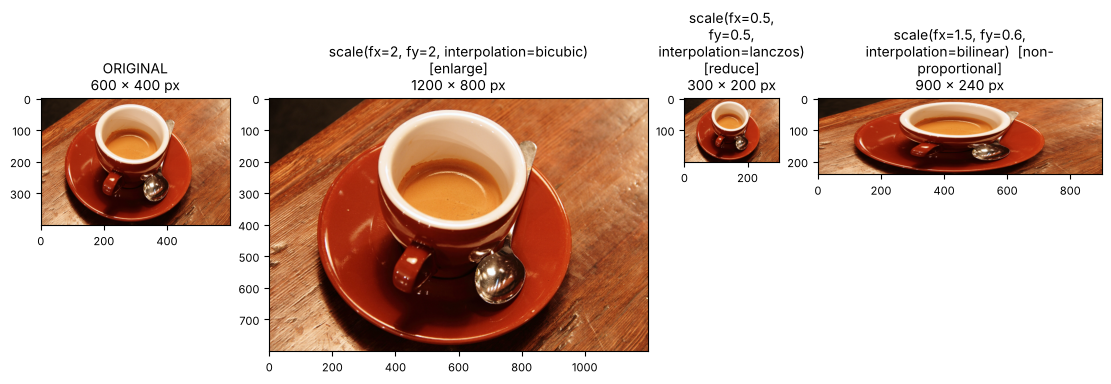

| Saved file | Operation | Parameters | Input W x H | Output W x H | Aspect W/H |
|---|---|---|---|---|---|
| scale_enlarge_2x_bicubic.png | scale | fx=2, fy=2, interpolation=bicubic | 600 x 400 | 1200 x 800 | 1.500 |
| scale_reduce_0.5x_lanczos.png | scale | fx=0.5, fy=0.5, interpolation=lanczos | 600 x 400 | 300 x 200 | 1.500 |
| scale_nonproportional_1.5x_0.6.png | scale | fx=1.5, fy=0.6, interpolation=bilinear | 600 x 400 | 900 x 240 | 3.750 |

Aspect ratio (W/H): original 1.500 | 2x 1.500 | 0.5x 1.500 | non-proportional 3.750  <- distorted


In [6]:
start = len(RUNS)
up   = run("scale", "scale_enlarge_2x_bicubic",       fx=2.0, fy=2.0, interpolation="bicubic")    # enlargement (proportional)
down = run("scale", "scale_reduce_0.5x_lanczos",      fx=0.5, fy=0.5, interpolation="lanczos")    # reduction (proportional)
nonp = run("scale", "scale_nonproportional_1.5x_0.6", fx=1.5, fy=0.6, interpolation="bilinear")   # non-proportional

show_row([(original, "ORIGINAL"),
          (up,   label_for("scale", {"fx": 2.0, "fy": 2.0, "interpolation": "bicubic"})   + "  [enlarge]"),
          (down, label_for("scale", {"fx": 0.5, "fy": 0.5, "interpolation": "lanczos"})   + "  [reduce]"),
          (nonp, label_for("scale", {"fx": 1.5, "fy": 0.6, "interpolation": "bilinear"})  + "  [non-proportional]")],
         "01_scaling")
runs_table(start)
print(f"Aspect ratio (W/H): original {W0/H0:.3f} | 2x {up.shape[1]/up.shape[0]:.3f} | 0.5x {down.shape[1]/down.shape[0]:.3f} "
      f"| non-proportional {nonp.shape[1]/nonp.shape[0]:.3f}  <- distorted")

### 5.2 Cropping
Coordinates are `(left, top, right, bottom)` with **right and bottom exclusive**, so the result has `right-left` columns and `bottom-top` rows. The coloured boxes mark the regions on the original.

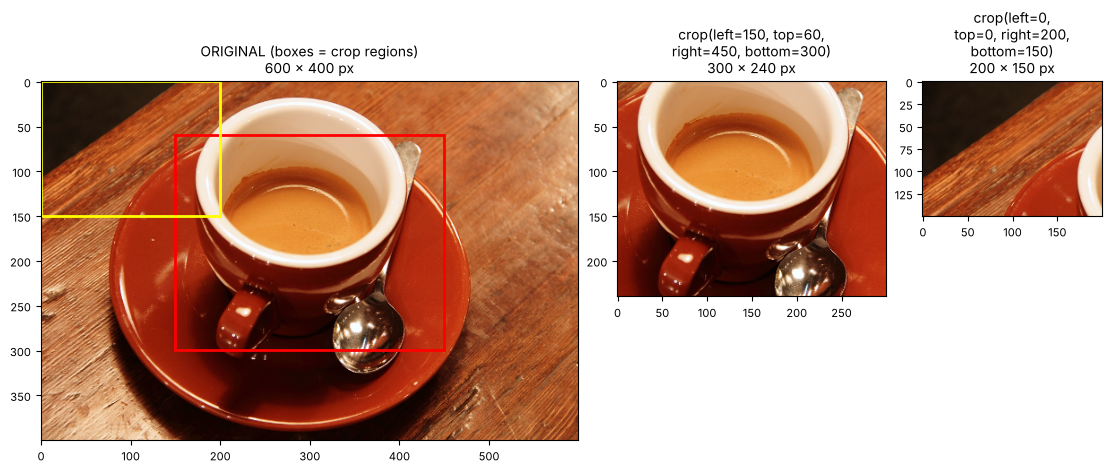

| Saved file | Operation | Parameters | Input W x H | Output W x H | Aspect W/H |
|---|---|---|---|---|---|
| crop_centre_region.png | crop | left=150, top=60, right=450, bottom=300 | 600 x 400 | 300 x 240 | 1.250 |
| crop_top_left_tile.png | crop | left=0, top=0, right=200, bottom=150 | 600 x 400 | 200 x 150 | 1.333 |

Check: c1.shape = (240, 300, 3) = (bottom-top, right-left, 3) = (240, 300, 3)


In [7]:
start = len(RUNS)
c1 = run("crop", "crop_centre_region",  left=150, top=60,  right=450, bottom=300)   # 300 x 240
c2 = run("crop", "crop_top_left_tile",  left=0,   top=0,   right=200, bottom=150)   # touches the image border (valid, 0 allowed)

show_row([(original, "ORIGINAL (boxes = crop regions)"),
          (c1, label_for("crop", {"left": 150, "top": 60, "right": 450, "bottom": 300})),
          (c2, label_for("crop", {"left": 0, "top": 0, "right": 200, "bottom": 150}))],
         "02_cropping", boxes={0: [(150, 60, 450, 300, "red"), (0, 0, 200, 150, "yellow")]})
runs_table(start)
print("Check: c1.shape =", c1.shape, "= (bottom-top, right-left, 3) =", (300 - 60, 450 - 150, 3))

### 5.3 Flipping — horizontal, vertical and both
Horizontal = mirror left↔right (about the vertical axis); vertical = top↔bottom; both = a 180° turn.

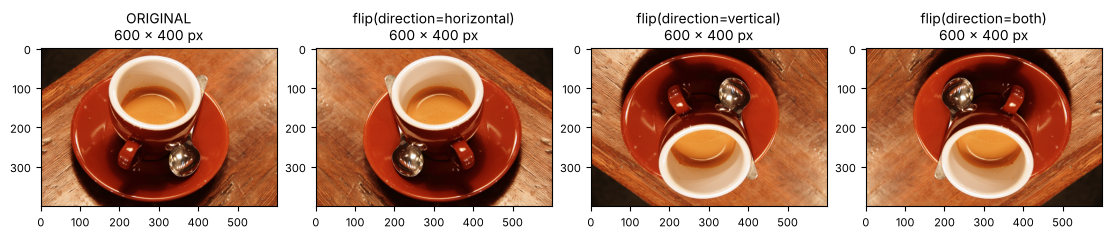

| Saved file | Operation | Parameters | Input W x H | Output W x H | Aspect W/H |
|---|---|---|---|---|---|
| flip_horizontal.png | flip | direction=horizontal | 600 x 400 | 600 x 400 | 1.500 |
| flip_vertical.png | flip | direction=vertical | 600 x 400 | 600 x 400 | 1.500 |
| flip_both.png | flip | direction=both | 600 x 400 | 600 x 400 | 1.500 |

flip both == rotate by 180 deg (np.rot90 twice): True


In [8]:
start = len(RUNS)
fh = run("flip", "flip_horizontal", direction="horizontal")
fv = run("flip", "flip_vertical",   direction="vertical")
fb = run("flip", "flip_both",       direction="both")

show_row([(original, "ORIGINAL"), (fh, "flip(direction=horizontal)"),
          (fv, "flip(direction=vertical)"), (fb, "flip(direction=both)")], "03_flipping")
runs_table(start)
print("flip both == rotate by 180 deg (np.rot90 twice):", np.array_equal(fb, np.rot90(original, 2)))

### 5.4 Translation — shifts in opposite directions
`tx` > 0 moves the picture **right**, `tx` < 0 **left**; `ty` > 0 moves it **down**, `ty` < 0 **up**. The canvas keeps the original size, so pixels that move past the border are **clipped (lost)** and the newly exposed strips are filled with **black** background.

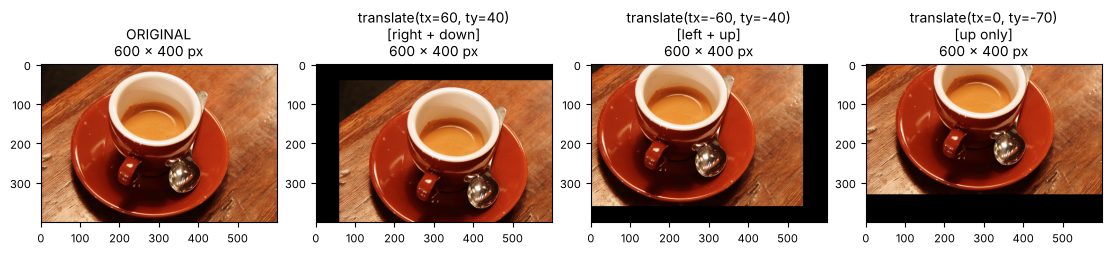

| Saved file | Operation | Parameters | Input W x H | Output W x H | Aspect W/H |
|---|---|---|---|---|---|
| translate_plus60_plus40.png | translate | tx=60, ty=40 | 600 x 400 | 600 x 400 | 1.500 |
| translate_minus60_minus40.png | translate | tx=-60, ty=-40 | 600 x 400 | 600 x 400 | 1.500 |
| translate_zero_minus70.png | translate | tx=0, ty=-70 | 600 x 400 | 600 x 400 | 1.500 |

tx=  60, ty=  40: kept 194,400 px, clipped/exposed 45,600 px (19.0% of the canvas) -> output stays 600 x 400
tx= -60, ty= -40: kept 194,400 px, clipped/exposed 45,600 px (19.0% of the canvas) -> output stays 600 x 400
tx=   0, ty= -70: kept 198,000 px, clipped/exposed 42,000 px (17.5% of the canvas) -> output stays 600 x 400


In [9]:
start = len(RUNS)
t1 = run("translate", "translate_plus60_plus40",   tx=60.0,  ty=40.0)     # right + down
t2 = run("translate", "translate_minus60_minus40", tx=-60.0, ty=-40.0)    # left + up (opposite direction)
t3 = run("translate", "translate_zero_minus70",    tx=0.0,   ty=-70.0)    # zero is a valid offset

show_row([(original, "ORIGINAL"),
          (t1, label_for("translate", {"tx": 60.0, "ty": 40.0}) + "  [right + down]"),
          (t2, label_for("translate", {"tx": -60.0, "ty": -40.0}) + "  [left + up]"),
          (t3, label_for("translate", {"tx": 0.0, "ty": -70.0}) + "  [up only]")], "04_translation")
runs_table(start)
for (tx, ty) in [(60, 40), (-60, -40), (0, -70)]:
    kept = (W0 - abs(tx)) * (H0 - abs(ty))
    print(f"tx={tx:>4}, ty={ty:>4}: kept {kept:,} px, clipped/exposed {W0*H0-kept:,} px ({100*(W0*H0-kept)/(W0*H0):.1f}% of the canvas) -> output stays {W0} x {H0}")

### 5.5 Rotation — positive and negative angles, with and without canvas expansion
Rotation is about the **image centre**. A **positive angle rotates counter-clockwise** as seen on screen; a negative angle rotates clockwise. With `expand=False` the canvas stays the same size and the corners are clipped; with `expand=True` the canvas grows to the bounding box of the rotated image so nothing is lost (the new corner areas are black).

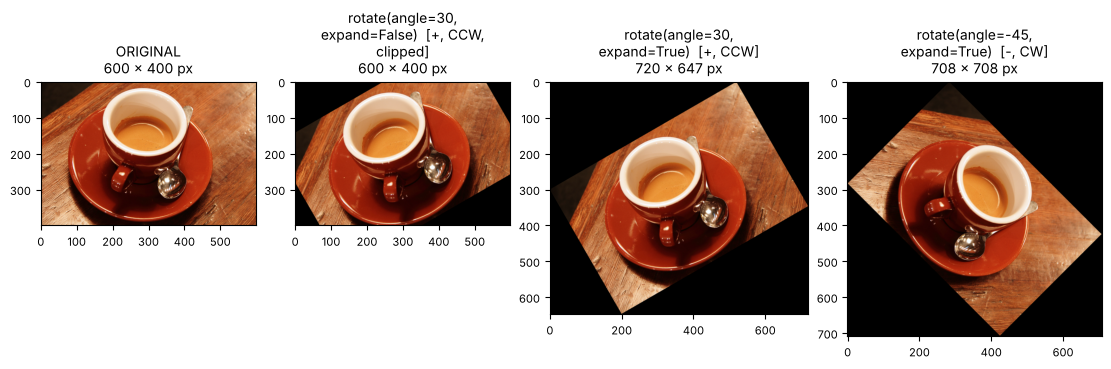

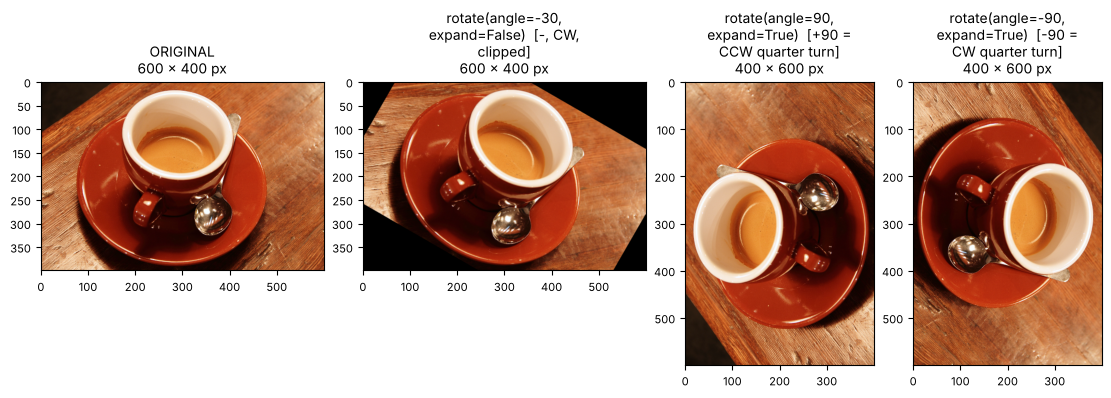

| Saved file | Operation | Parameters | Input W x H | Output W x H | Aspect W/H |
|---|---|---|---|---|---|
| rotate_plus30_noexpand.png | rotate | angle=30, expand=False | 600 x 400 | 600 x 400 | 1.500 |
| rotate_plus30_expand.png | rotate | angle=30, expand=True | 600 x 400 | 720 x 647 | 1.113 |
| rotate_minus45_expand.png | rotate | angle=-45, expand=True | 600 x 400 | 708 x 708 | 1.000 |
| rotate_minus30_noexpand.png | rotate | angle=-30, expand=False | 600 x 400 | 600 x 400 | 1.500 |
| rotate_plus90_expand.png | rotate | angle=90, expand=True | 600 x 400 | 400 x 600 | 0.667 |
| rotate_minus90_expand.png | rotate | angle=-90, expand=True | 600 x 400 | 400 x 600 | 0.667 |

angle   30: expanded canvas = ceil(W|cos|+H|sin|) x ceil(W|sin|+H|cos|) = 720 x 647
angle  -45: expanded canvas = ceil(W|cos|+H|sin|) x ceil(W|sin|+H|cos|) = 708 x 708


In [10]:
start = len(RUNS)
r1 = run("rotate", "rotate_plus30_noexpand",  angle=30.0,  expand=False)
r2 = run("rotate", "rotate_plus30_expand",    angle=30.0,  expand=True)
r3 = run("rotate", "rotate_minus45_expand",   angle=-45.0, expand=True)
r4 = run("rotate", "rotate_minus30_noexpand", angle=-30.0, expand=False)
r5 = run("rotate", "rotate_plus90_expand",    angle=90.0,  expand=True)
r6 = run("rotate", "rotate_minus90_expand",   angle=-90.0, expand=True)

show_row([(original, "ORIGINAL"),
          (r1, "rotate(angle=30, expand=False)  [+, CCW, clipped]"),
          (r2, "rotate(angle=30, expand=True)  [+, CCW]"),
          (r3, "rotate(angle=-45, expand=True)  [-, CW]")], "05_rotation_a")
show_row([(original, "ORIGINAL"),
          (r4, "rotate(angle=-30, expand=False)  [-, CW, clipped]"),
          (r5, "rotate(angle=90, expand=True)  [+90 = CCW quarter turn]"),
          (r6, "rotate(angle=-90, expand=True)  [-90 = CW quarter turn]")], "05_rotation_b")
runs_table(start)

for ang in (30, -45):
    a = math.radians(abs(ang)); c_, s_ = math.cos(a), math.sin(a)
    print(f"angle {ang:>4}: expanded canvas = ceil(W|cos|+H|sin|) x ceil(W|sin|+H|cos|) = "
          f"{math.ceil(round(W0*c_+H0*s_,6))} x {math.ceil(round(W0*s_+H0*c_,6))}")

### 5.6 Custom values typed at the prompts (with mistakes and corrections)
Three sessions use the real prompt loop. Each contains wrong entries (unknown operation, non-numeric text, `nan`, bad interpolation name, an invalid crop region, an invalid yes/no) which are **rejected with a message and asked again** — no crash, no silent default.

Set `USE_REAL_INPUT = True` below to type your own values instead.


===== Session: scale =====
Operation [scale/crop/flip/translate/rotate, q = quit]: zoom
  x Error: unknown operation 'zoom'. Choose one of ['crop', 'flip', 'rotate', 'scale', 'translate'].
Operation [scale/crop/flip/translate/rotate, q = quit]: scale
  Horizontal scale factor fx (> 0): abc
  x Error: 'fx': 'abc' is not a number.  -> please enter it again.
  Horizontal scale factor fx (> 0): 1.5
  Vertical scale factor fy (> 0): nan
  x Error: 'fy': 'nan' is not finite (NaN and infinity are rejected).  -> please enter it again.
  Vertical scale factor fy (> 0): 0.75
  Interpolation [nearest/bilinear/bicubic/lanczos]: cubic
  x Error: 'interpolation' must be one of ['nearest', 'bilinear', 'bicubic', 'lanczos'], got 'cubic'.  -> please enter it again.
  Interpolation [nearest/bilinear/bicubic/lanczos]: bicubic
  OK: scale {'fx': 1.5, 'fy': 0.75, 'interpolation': 'bicubic'} -> output 900 x 300 px


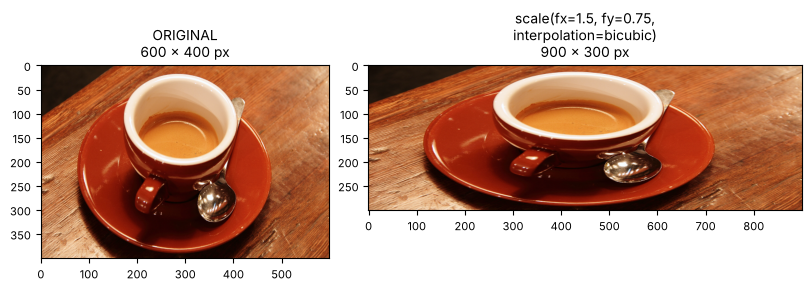


===== Session: crop =====
Operation [scale/crop/flip/translate/rotate, q = quit]: crop
  left (int): 300
  top (int): 50
  right (int, exclusive): 100
  bottom (int, exclusive): 250
  x Error: Invalid horizontal crop range: need 0 <= left < right <= 600, got left=300, right=100.  -> let's enter this operation again.
Operation [scale/crop/flip/translate/rotate, q = quit]: crop
  left (int): 100
  top (int): 50
  right (int, exclusive): 400
  bottom (int, exclusive): 300
  OK: crop {'left': 100, 'top': 50, 'right': 400, 'bottom': 300} -> output 300 x 250 px


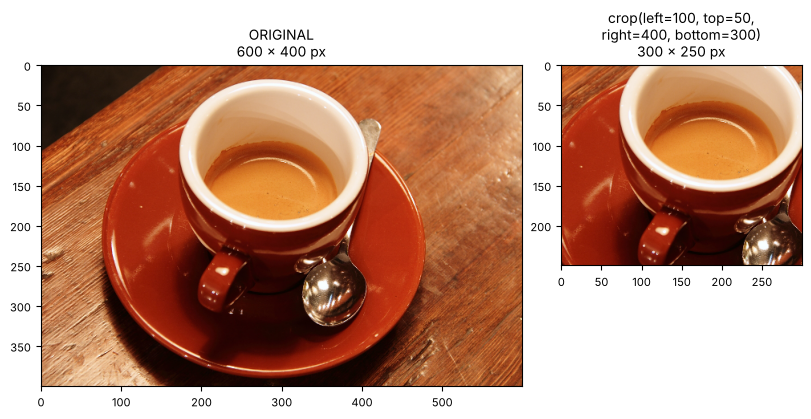


===== Session: rotate =====
Operation [scale/crop/flip/translate/rotate, q = quit]: rotate
  Angle in degrees (+ = counter-clockwise): -20
  Expand the canvas to fit the whole rotated image? [yes/no]: maybe
  x Error: 'expand': 'maybe' is not a yes/no answer (type yes or no).  -> please enter it again.
  Expand the canvas to fit the whole rotated image? [yes/no]: yes
  OK: rotate {'angle': -20.0, 'expand': True} -> output 701 x 582 px


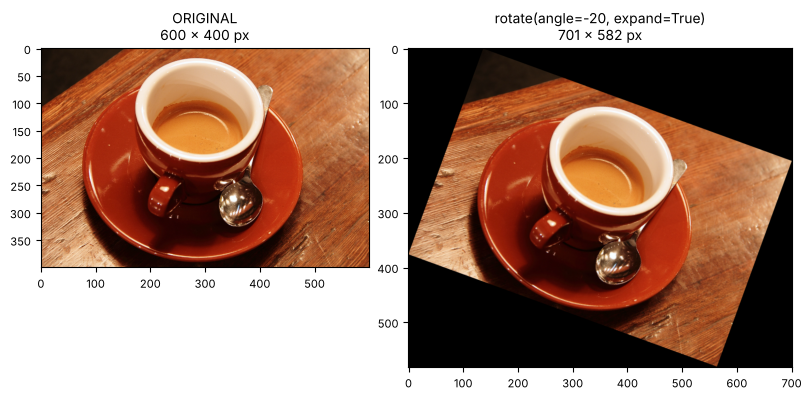

In [11]:
USE_REAL_INPUT = False      # True -> use real input() prompts in Jupyter instead of the scripted answers

SESSIONS = {
 "scale": ["zoom", "scale", "abc", "1.5", "nan", "0.75", "cubic", "bicubic"],
 "crop":  ["crop", "300", "50", "100", "250",          # right(100) <= left(300) -> rejected by transform, ask again
           "crop", "100", "50", "400", "300"],
 "rotate": ["rotate", "-20", "maybe", "yes"],
}
REPORT["interactive"] = {}
for key, answers in SESSIONS.items():
    print(f"\n===== Session: {key} =====")
    log = []
    ask = input if USE_REAL_INPUT else scripted(answers, log)
    got = interactive_transform(original, ask=ask, log=log)
    if got is None:
        continue
    out, op, params = got
    save_result(out, f"interactive_{key}")
    RUNS.append({"file": f"interactive_{key}.png", "op": op, "params": params, "in_w": W0, "in_h": H0,
                 "out_w": out.shape[1], "out_h": out.shape[0]})
    REPORT["interactive"][key] = {"transcript": log, "op": op, "params": params, "out": [out.shape[1], out.shape[0]]}
    show_row([(original, "ORIGINAL"), (out, label_for(op, params))], f"06_interactive_{key}", fig_w=8)

## 6. Interpolation comparison on one enlarged patch
A 40 × 40 patch containing strong edges is cropped (with `transform`), then enlarged **8×** with each interpolation method (also through `transform`). The patch position is chosen automatically as the window with the most edge energy (largest Laplacian response).

Patch: left=22, top=193, size 40 x 40  ->  enlarged 320 x 320 for every method


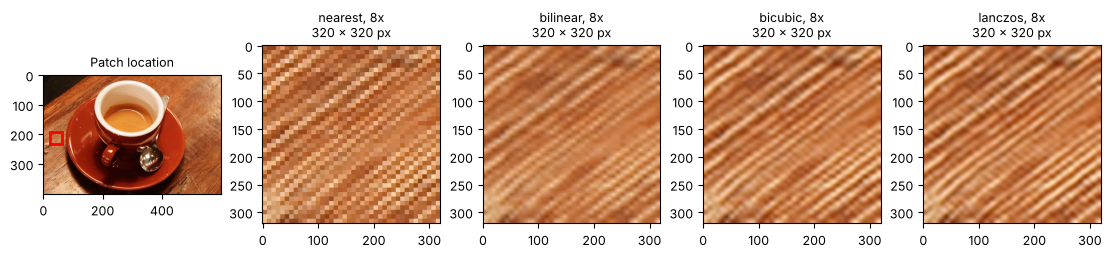

| Method | Sharpness (variance of Laplacian) | Pixels outside source colour range | Distinct colours |
|---|---|---|---|
| nearest | 937.8 | 0.00 % | 1569 |
| bilinear | 8.7 | 0.00 % | 28226 |
| bicubic | 8.5 | 0.21 % | 39909 |
| lanczos | 9.5 | 0.42 % | 42929 |

Distinct colours in the 40x40 source patch: 1569


In [12]:
def pick_patch(img, size=40):
    g = cv.cvtColor(img, cv.COLOR_RGB2GRAY).astype(np.float32)
    lap = np.abs(cv.Laplacian(g, cv.CV_32F))
    score = cv.boxFilter(lap, -1, (size, size), normalize=False, borderType=cv.BORDER_CONSTANT)
    half = size // 2
    valid = score[half:img.shape[0] - half, half:img.shape[1] - half]
    top, left = np.unravel_index(np.argmax(valid), valid.shape)
    return int(left), int(top)

PS, K = 40, 8.0
pl, pt = pick_patch(original, PS)
patch = transform(original, "crop", left=pl, top=pt, right=pl + PS, bottom=pt + PS)
print(f"Patch: left={pl}, top={pt}, size {PS} x {PS}  ->  enlarged {int(PS*K)} x {int(PS*K)} for every method")

methods = ["nearest", "bilinear", "bicubic", "lanczos"]
ups = {m: run("scale", f"interp_patch_{m}", source=patch, fx=K, fy=K, interpolation=m) for m in methods}

fig, axes = plt.subplots(1, 5, figsize=(11, 2.9), layout="constrained")
axes[0].imshow(original); axes[0].set_title("Patch location", fontsize=9)
axes[0].add_patch(Rectangle((pl - 0.5, pt - 0.5), PS, PS, fill=False, ec="red", lw=2))
for ax, m in zip(axes[1:], methods):
    ax.imshow(ups[m], vmin=0, vmax=255)
    ax.set_title(f"{m}, {K:g}x\n{ups[m].shape[1]} x {ups[m].shape[0]} px", fontsize=9)
fig.savefig(os.path.join(FIG_DIR, "07_interpolation_comparison.png"), dpi=110, bbox_inches="tight")
plt.show()

# measurable differences
lo, hi = patch.min(axis=(0, 1)), patch.max(axis=(0, 1))
rows, INTERP = [], []
for m in methods:
    u = ups[m]
    sharp = float(cv.Laplacian(cv.cvtColor(u, cv.COLOR_RGB2GRAY), cv.CV_64F).var())
    over  = float(((u < lo) | (u > hi)).any(axis=2).mean() * 100)
    uniq  = int(len(np.unique(u.reshape(-1, 3), axis=0)))
    INTERP.append({"method": m, "sharpness": round(sharp, 1), "overshoot_pct": round(over, 2), "unique_colours": uniq})
    rows.append((m, f"{sharp:.1f}", f"{over:.2f} %", uniq))
show_table(["Method", "Sharpness (variance of Laplacian)", "Pixels outside source colour range", "Distinct colours"], rows)
REPORT["interp"] = {"patch": {"left": pl, "top": pt, "size": PS, "factor": K}, "metrics": INTERP,
                    "source_unique_colours": int(len(np.unique(patch.reshape(-1, 3), axis=0)))}
print("Distinct colours in the 40x40 source patch:", REPORT["interp"]["source_unique_colours"])

**Visible differences (8× enlargement of the wood-grain patch)**

| Method | What the eye sees | Measured (this patch) |
|---|---|---|
| **Nearest-neighbour** | Hard 8 × 8 blocks and jagged, staircase edges; every output pixel is a copy of one source pixel, so no new colours appear. | Same 1569 distinct colours as the source; the very large Laplacian value comes from the artificial block edges, not from real detail. |
| **Bilinear** | Blocks disappear, the grain becomes smooth but visibly soft/blurred (average of 4 neighbours). | No pixel outside the source colour range (no overshoot). |
| **Bicubic** | Smooth like bilinear but the grain ridges look crisper and have a little more contrast (16 neighbours, cubic kernel). | Slightly more sharpness than bilinear in the eye; faint overshoot (0.21 % of pixels outside the source range = tiny halos). |
| **Lanczos** | Crispest result: strongest ridge contrast and finest detail (8 × 8 windowed-sinc kernel). | Highest sharpness of the smooth methods and the most overshoot (0.42 %): mild ringing/halo risk near strong edges. |

**Trade-off:** nearest is fastest and keeps exact values but looks blocky; bilinear is smooth but soft; bicubic and Lanczos preserve more detail at higher cost and with slight overshoot.

## 7. Rejected inputs
Every case below is run through `transform` (or `load_image`) and must be refused with a clear `TransformError` message — no unhandled crash. At least one rejected input is shown for **every** operation (flip uses an unsupported direction; rotate uses a non-numeric and non-finite angle).

In [13]:
def attempt(label, group, fn):
    try:
        fn()
        return (group, label, "ACCEPTED (unexpected!)", False)
    except TransformError as e:
        return (group, label, f"REJECTED: {e}", True)
    except Exception as e:                                   # anything else would be an unhandled crash
        return (group, label, f"UNEXPECTED {type(e).__name__}: {e}", False)

# a text file that is not an image, to test decoding failure
with open("not_an_image.txt", "w") as f:
    f.write("this is plain text, not an image")

T = lambda op, **p: (lambda: transform(original, op, **p))
cases = [
 ("Image",     "load a file that does not exist",            lambda: load_image("no_such_file.png")),
 ("Image",     "load a file that is not an image",           lambda: load_image("not_an_image.txt")),
 ("Image",     "transform an empty (0 x 5) array",           lambda: transform(np.zeros((0, 5, 3), np.uint8), "flip", direction="both")),
 ("Operation", "unknown operation 'shear'",                  T("shear", k=1)),
 ("Operation", "missing parameter (scale without fy)",       T("scale", fx=2.0, interpolation="bilinear")),
 ("Operation", "unexpected extra parameter (flip, angle=5)", T("flip", direction="both", angle=5)),
 ("Scale",     "fx = 0",                                     T("scale", fx=0, fy=1, interpolation="bilinear")),
 ("Scale",     "fy = -2 (negative)",                         T("scale", fx=1, fy=-2, interpolation="bilinear")),
 ("Scale",     "fx = NaN",                                   T("scale", fx=float("nan"), fy=1, interpolation="bilinear")),
 ("Scale",     "fx = 'abc' (non-numeric)",                   T("scale", fx="abc", fy=1, interpolation="bilinear")),
 ("Scale",     "fx = 0.0005 -> 0-pixel width (empty image)", T("scale", fx=0.0005, fy=1, interpolation="bilinear")),
 ("Scale",     "fx = fy = 100 -> output beyond size limit",  T("scale", fx=100, fy=100, interpolation="nearest")),
 ("Scale",     "unsupported interpolation 'cubic'",          T("scale", fx=2, fy=2, interpolation="cubic")),
 ("Crop",      "right <= left (left=300, right=100)",        T("crop", left=300, top=0, right=100, bottom=100)),
 ("Crop",      f"right beyond width (right={W0+1})",         T("crop", left=0, top=0, right=W0 + 1, bottom=100)),
 ("Crop",      "negative left (-5)",                         T("crop", left=-5, top=0, right=100, bottom=100)),
 ("Crop",      "non-integer coordinate (top=10.5)",          T("crop", left=0, top=10.5, right=100, bottom=100)),
 ("Flip",      "unsupported direction 'diagonal'",           T("flip", direction="diagonal")),
 ("Translate", "tx = NaN",                                   T("translate", tx=float("nan"), ty=0)),
 ("Translate", "ty = 'abc' (non-numeric)",                   T("translate", tx=0, ty="abc")),
 ("Translate", "tx = infinity",                              T("translate", tx=float("inf"), ty=0)),
 ("Rotate",    "angle = 'abc' (non-numeric)",                T("rotate", angle="abc", expand=False)),
 ("Rotate",    "angle = infinity (non-finite)",              T("rotate", angle=float("inf"), expand=True)),
 ("Rotate",    "angle = NaN (non-finite)",                   T("rotate", angle=float("nan"), expand=True)),
 ("Rotate",    "expand = 'yes' (not a boolean)",             T("rotate", angle=10, expand="yes")),
]
results = [attempt(lbl, grp, fn) for grp, lbl, fn in cases]
os.remove("not_an_image.txt")
show_table(["#", "Operation", "Invalid input", "Outcome"], [(i + 1, g, l, o) for i, (g, l, o, ok) in enumerate(results)])
REPORT["rejected"] = [{"group": g, "input": l, "outcome": o, "ok": ok} for g, l, o, ok in results]
print(f"{sum(ok for *_, ok in results)} / {len(results)} invalid inputs were cleanly rejected with a TransformError.")

# text-level validation (what a user types) happens BEFORE transform is called
print("\nTyped-text validation examples:")
for fn_name, fn, text in [("parse_float", parse_float, "abc"), ("parse_float", parse_float, "nan"),
                          ("parse_float", parse_float, "inf"), ("parse_float", parse_float, ""),
                          ("parse_int", parse_int, "10.5"), ("parse_bool", parse_bool, "maybe")]:
    try:
        print(f"  {fn_name}({text!r:7}) ->", fn("value", text))
    except TransformError as e:
        print(f"  {fn_name}({text!r:7}) -> rejected:", e)

| # | Operation | Invalid input | Outcome |
|---|---|---|---|
| 1 | Image | load a file that does not exist | REJECTED: Image file does not exist: 'no_such_file.png'. |
| 2 | Image | load a file that is not an image | REJECTED: File exists but could not be decoded as an image: 'not_an_image.txt'. |
| 3 | Image | transform an empty (0 x 5) array | REJECTED: image is empty (shape (0, 5, 3)); width and height must be non-zero. |
| 4 | Operation | unknown operation 'shear' | REJECTED: Unknown operation 'shear'. Supported: ['crop', 'flip', 'rotate', 'scale', 'translate']. |
| 5 | Operation | missing parameter (scale without fy) | REJECTED: Operation 'scale' is missing required parameter(s): ['fy']. |
| 6 | Operation | unexpected extra parameter (flip, angle=5) | REJECTED: Operation 'flip' does not accept parameter(s): ['angle']. Expected: ['direction']. |
| 7 | Scale | fx = 0 | REJECTED: Scale factors must be greater than zero, got fx=0, fy=1. |
| 8 | Scale | fy = -2 (negative) | REJECTED: Scale factors must be greater than zero, got fx=1, fy=-2. |
| 9 | Scale | fx = NaN | REJECTED: 'fx' must be finite, got nan (NaN and infinity are rejected). |
| 10 | Scale | fx = 'abc' (non-numeric) | REJECTED: 'fx' must be a number, got str ('abc'). |
| 11 | Scale | fx = 0.0005 -> 0-pixel width (empty image) | REJECTED: Output would be 0 x 400 px; both dimensions must be at least 1 pixel (empty image). |
| 12 | Scale | fx = fy = 100 -> output beyond size limit | REJECTED: Output 60000 x 40000 px exceeds the maximum allowed size (each side <= 8000 px, total <= 25,000,000 px). |
| 13 | Scale | unsupported interpolation 'cubic' | REJECTED: 'interpolation' must be one of ['nearest', 'bilinear', 'bicubic', 'lanczos'], got 'cubic'. |
| 14 | Crop | right <= left (left=300, right=100) | REJECTED: Invalid horizontal crop range: need 0 <= left < right <= 600, got left=300, right=100. |
| 15 | Crop | right beyond width (right=601) | REJECTED: Invalid horizontal crop range: need 0 <= left < right <= 600, got left=0, right=601. |
| 16 | Crop | negative left (-5) | REJECTED: Invalid horizontal crop range: need 0 <= left < right <= 600, got left=-5, right=100. |
| 17 | Crop | non-integer coordinate (top=10.5) | REJECTED: 'top' must be a whole number of pixels, got 10.5. |
| 18 | Flip | unsupported direction 'diagonal' | REJECTED: 'direction' must be one of ['horizontal', 'vertical', 'both'], got 'diagonal'. |
| 19 | Translate | tx = NaN | REJECTED: 'tx' must be finite, got nan (NaN and infinity are rejected). |
| 20 | Translate | ty = 'abc' (non-numeric) | REJECTED: 'ty' must be a number, got str ('abc'). |
| 21 | Translate | tx = infinity | REJECTED: 'tx' must be finite, got inf (NaN and infinity are rejected). |
| 22 | Rotate | angle = 'abc' (non-numeric) | REJECTED: 'angle' must be a number, got str ('abc'). |
| 23 | Rotate | angle = infinity (non-finite) | REJECTED: 'angle' must be finite, got inf (NaN and infinity are rejected). |
| 24 | Rotate | angle = NaN (non-finite) | REJECTED: 'angle' must be finite, got nan (NaN and infinity are rejected). |
| 25 | Rotate | expand = 'yes' (not a boolean) | REJECTED: 'expand' must be True or False, got 'yes'. |

25 / 25 invalid inputs were cleanly rejected with a TransformError.

Typed-text validation examples:
  parse_float('abc'  ) -> rejected: 'value': 'abc' is not a number.
  parse_float('nan'  ) -> rejected: 'value': 'nan' is not finite (NaN and infinity are rejected).
  parse_float('inf'  ) -> rejected: 'value': 'inf' is not finite (NaN and infinity are rejected).
  parse_float(''     ) -> rejected: 'value' is empty; please type a number.
  parse_int('10.5' ) -> rejected: 'value': '10.5' is not a whole number.
  parse_bool('maybe') -> rejected: 'value': 'maybe' is not a yes/no answer (type yes or no).


### Valid boundary inputs that must **not** be rejected
Zero offsets, zero angle, negative offsets/angles, a scale factor of 1, and a crop of the whole image are all legitimate.

In [14]:
valid_cases = [
 ("Translate", "tx=0, ty=0 (zero offsets)",         "translate", dict(tx=0, ty=0)),
 ("Translate", "tx=-25, ty=-10 (negative offsets)", "translate", dict(tx=-25, ty=-10)),
 ("Rotate",    "angle=0, expand=False",              "rotate",    dict(angle=0, expand=False)),
 ("Rotate",    "angle=-45.5, expand=True",           "rotate",    dict(angle=-45.5, expand=True)),
 ("Rotate",    "angle=720 (two full turns)",         "rotate",    dict(angle=720, expand=False)),
 ("Scale",     "fx=1, fy=1",                         "scale",     dict(fx=1, fy=1, interpolation="bicubic")),
 ("Crop",      "whole image (0, 0, W, H)",           "crop",      dict(left=0, top=0, right=W0, bottom=H0)),
 ("Crop",      "single pixel (10, 10, 11, 11)",      "crop",      dict(left=10, top=10, right=11, bottom=11)),
 ("Flip",      "direction='Horizontal ' (case/space)", "flip",    dict(direction="Horizontal ")),
]
rows, valid_rec = [], []
for grp, lbl, op, p in valid_cases:
    out = transform(original, op, **p)
    rows.append((grp, lbl, f"accepted -> {out.shape[1]} x {out.shape[0]} px"))
    valid_rec.append({"group": grp, "input": lbl, "outcome": f"accepted -> {out.shape[1]} x {out.shape[0]} px"})
show_table(["Operation", "Valid boundary input", "Outcome"], rows)
REPORT["accepted"] = valid_rec

| Operation | Valid boundary input | Outcome |
|---|---|---|
| Translate | tx=0, ty=0 (zero offsets) | accepted -> 600 x 400 px |
| Translate | tx=-25, ty=-10 (negative offsets) | accepted -> 600 x 400 px |
| Rotate | angle=0, expand=False | accepted -> 600 x 400 px |
| Rotate | angle=-45.5, expand=True | accepted -> 706 x 709 px |
| Rotate | angle=720 (two full turns) | accepted -> 600 x 400 px |
| Scale | fx=1, fy=1 | accepted -> 600 x 400 px |
| Crop | whole image (0, 0, W, H) | accepted -> 600 x 400 px |
| Crop | single pixel (10, 10, 11, 11) | accepted -> 1 x 1 px |
| Flip | direction='Horizontal ' (case/space) | accepted -> 600 x 400 px |

## 8. Identity and correctness checks
Each row states the **expected** behaviour, the **actual** behaviour measured on the arrays, and **Pass / Fail**.

In [15]:
CHECKS = []
def check(name, expected, ok, actual):
    CHECKS.append({"name": name, "expected": expected, "actual": actual, "result": "Pass" if ok else "Fail"})

def eq(a, b): return bool(np.array_equal(a, b))

# --- identity cases required by the task
o = transform(original, "translate", tx=0, ty=0)
check("Translation tx=0, ty=0", "output identical to input", eq(o, original), f"array_equal = {eq(o, original)}, shape {o.shape}")
for m in methods:
    o = transform(original, "scale", fx=1, fy=1, interpolation=m)
    check(f"Scale fx=fy=1 ({m})", "output identical to input", eq(o, original), f"array_equal = {eq(o, original)}, shape {o.shape}")
for ex in (False, True):
    o = transform(original, "rotate", angle=0, expand=ex)
    check(f"Rotation angle=0, expand={ex}", "output identical to input", eq(o, original), f"array_equal = {eq(o, original)}, shape {o.shape}")

# --- further correctness checks
o = transform(original, "crop", left=0, top=0, right=W0, bottom=H0)
check("Crop of the whole image", "identical to input", eq(o, original), f"array_equal = {eq(o, original)}")
o = transform(original, "crop", left=150, top=60, right=450, bottom=300)
check("Crop (150,60,450,300) is the NumPy slice [60:300, 150:450]", "shape (240, 300, 3) and same pixels",
      eq(o, original[60:300, 150:450]) and o.shape == (240, 300, 3), f"shape {o.shape}, equal to slice = {eq(o, original[60:300, 150:450])}")
for d in ("horizontal", "vertical", "both"):
    o = transform(transform(original, "flip", direction=d), "flip", direction=d)
    check(f"Flip {d} applied twice", "returns the original", eq(o, original), f"array_equal = {eq(o, original)}")
check("Flip horizontal == original[:, ::-1]", "same pixels",
      eq(transform(original, "flip", direction="horizontal"), original[:, ::-1]), "array_equal = " + str(eq(transform(original, "flip", direction="horizontal"), original[:, ::-1])))
check("Flip vertical == original[::-1, :]", "same pixels",
      eq(transform(original, "flip", direction="vertical"), original[::-1, :]), "array_equal = " + str(eq(transform(original, "flip", direction="vertical"), original[::-1, :])))

tx, ty = 60, 40
exp = np.zeros_like(original); exp[ty:, tx:] = original[:H0 - ty, :W0 - tx]
o = transform(original, "translate", tx=tx, ty=ty)
check("Translate (+60,+40): content moves right/down, rest is black", "o[40:,60:] == original[:-40,:-60]; exposed strips = 0",
      eq(o, exp) and o.shape == original.shape, f"array_equal = {eq(o, exp)}, canvas {o.shape[1]} x {o.shape[0]}")
tx, ty = -60, -40
exp = np.zeros_like(original); exp[:H0 + ty, :W0 + tx] = original[-ty:, -tx:]
o = transform(original, "translate", tx=tx, ty=ty)
check("Translate (-60,-40): content moves left/up, rest is black", "o[:-40,:-60] == original[40:,60:]; exposed strips = 0",
      eq(o, exp), f"array_equal = {eq(o, exp)}, canvas {o.shape[1]} x {o.shape[0]}")

o = transform(original, "rotate", angle=90, expand=True)
check("Rotate +90, expand=True is a counter-clockwise quarter turn", "equals np.rot90(original, 1), shape (W, H)",
      eq(o, np.rot90(original, 1)), f"array_equal = {eq(o, np.rot90(original, 1))}, shape {o.shape[1]} x {o.shape[0]}")
o = transform(original, "rotate", angle=-90, expand=True)
check("Rotate -90, expand=True is a clockwise quarter turn", "equals np.rot90(original, -1), shape (W, H)",
      eq(o, np.rot90(original, -1)), f"array_equal = {eq(o, np.rot90(original, -1))}, shape {o.shape[1]} x {o.shape[0]}")
o = transform(original, "rotate", angle=360, expand=False)
check("Rotate 360 deg is the identity", "identical to input", eq(o, original), f"array_equal = {eq(o, original)}")
o = transform(original, "rotate", angle=30, expand=False)
check("Rotate keeps canvas size when expand=False", f"{W0} x {H0}", o.shape == original.shape, f"{o.shape[1]} x {o.shape[0]}")

o = transform(original, "scale", fx=1.5, fy=0.6, interpolation="bilinear")
check("Scale output size = round(W*fx) x round(H*fy)", f"{round(W0*1.5)} x {round(H0*0.6)}",
      o.shape[:2] == (round(H0 * 0.6), round(W0 * 1.5)), f"{o.shape[1]} x {o.shape[0]}")

check("transform never modified the original array", "SHA-256 unchanged and array still read-only",
      hashlib.sha256(original.tobytes()).hexdigest() == ORIGINAL_SHA and not original.flags.writeable,
      "hash identical = " + str(hashlib.sha256(original.tobytes()).hexdigest() == ORIGINAL_SHA))

show_table(["#", "Check", "Expected", "Actual", "Result"],
           [(i + 1, c["name"], c["expected"], c["actual"], c["result"]) for i, c in enumerate(CHECKS)])
REPORT["checks"] = CHECKS
print(f"{sum(c['result'] == 'Pass' for c in CHECKS)} / {len(CHECKS)} checks passed.")
assert all(c["result"] == "Pass" for c in CHECKS), "A check failed!"
assert all(r["ok"] for r in REPORT["rejected"]), "An invalid input was not cleanly rejected!"

| # | Check | Expected | Actual | Result |
|---|---|---|---|---|
| 1 | Translation tx=0, ty=0 | output identical to input | array_equal = True, shape (400, 600, 3) | Pass |
| 2 | Scale fx=fy=1 (nearest) | output identical to input | array_equal = True, shape (400, 600, 3) | Pass |
| 3 | Scale fx=fy=1 (bilinear) | output identical to input | array_equal = True, shape (400, 600, 3) | Pass |
| 4 | Scale fx=fy=1 (bicubic) | output identical to input | array_equal = True, shape (400, 600, 3) | Pass |
| 5 | Scale fx=fy=1 (lanczos) | output identical to input | array_equal = True, shape (400, 600, 3) | Pass |
| 6 | Rotation angle=0, expand=False | output identical to input | array_equal = True, shape (400, 600, 3) | Pass |
| 7 | Rotation angle=0, expand=True | output identical to input | array_equal = True, shape (400, 600, 3) | Pass |
| 8 | Crop of the whole image | identical to input | array_equal = True | Pass |
| 9 | Crop (150,60,450,300) is the NumPy slice [60:300, 150:450] | shape (240, 300, 3) and same pixels | shape (240, 300, 3), equal to slice = True | Pass |
| 10 | Flip horizontal applied twice | returns the original | array_equal = True | Pass |
| 11 | Flip vertical applied twice | returns the original | array_equal = True | Pass |
| 12 | Flip both applied twice | returns the original | array_equal = True | Pass |
| 13 | Flip horizontal == original[:, ::-1] | same pixels | array_equal = True | Pass |
| 14 | Flip vertical == original[::-1, :] | same pixels | array_equal = True | Pass |
| 15 | Translate (+60,+40): content moves right/down, rest is black | o[40:,60:] == original[:-40,:-60]; exposed strips = 0 | array_equal = True, canvas 600 x 400 | Pass |
| 16 | Translate (-60,-40): content moves left/up, rest is black | o[:-40,:-60] == original[40:,60:]; exposed strips = 0 | array_equal = True, canvas 600 x 400 | Pass |
| 17 | Rotate +90, expand=True is a counter-clockwise quarter turn | equals np.rot90(original, 1), shape (W, H) | array_equal = True, shape 400 x 600 | Pass |
| 18 | Rotate -90, expand=True is a clockwise quarter turn | equals np.rot90(original, -1), shape (W, H) | array_equal = True, shape 400 x 600 | Pass |
| 19 | Rotate 360 deg is the identity | identical to input | array_equal = True | Pass |
| 20 | Rotate keeps canvas size when expand=False | 600 x 400 | 600 x 400 | Pass |
| 21 | Scale output size = round(W*fx) x round(H*fy) | 900 x 240 | 900 x 240 | Pass |
| 22 | transform never modified the original array | SHA-256 unchanged and array still read-only | hash identical = True | Pass |

22 / 22 checks passed.


## 9. Observations

**1. Image coordinates vs array indexing.** Image (Cartesian-style) coordinates are written **(x, y)** with the origin at the **top-left**, x growing to the right (columns) and y growing **downward** (rows). A NumPy image is indexed **[row, column] = [y, x]** and its shape is **(height, width, channels)** — here `(400, 600, 3)` for a 600 × 400 picture. OpenCV functions that take a size or a point use the image order — `cv.resize(img, (width, height))`, `warpAffine(..., (width, height))` — whereas slicing uses array order — `img[top:bottom, left:right]`. Mixing the two (for example `width, height = img.shape[:2]`) silently swaps the dimensions. A pixel with index *i* covers the interval *i ± 0.5*, so the centre of a W × H image is at ((W−1)/2, (H−1)/2), which is the rotation centre used above.

**2. Aspect-ratio distortion.** The aspect ratio W/H is preserved only when `fx = fy`. With `fx = 1.5, fy = 0.6` the ratio changes from **1.500 to 3.750**, i.e. the picture is stretched by fx/fy = 2.5 horizontally relative to vertically — the cup looks wide and flattened. Proportional scaling (2× and 0.5×) keeps the ratio at 1.500.

**3. Rotation canvas expansion.** With `expand=False` the canvas stays 600 × 400, so the corners of the rotated picture are **clipped** and black wedges appear. With `expand=True` the canvas grows to the bounding box ceil(W|cos θ| + H|sin θ|) × ceil(W|sin θ| + H|cos θ|) — **720 × 647** for 30° and **708 × 708** for 45° — so nothing is lost, at the price of more black background. A **positive angle rotates counter-clockwise** on screen (confirmed by the check that +90° with expansion equals `np.rot90(img, 1)`), a negative angle clockwise.

**4. Translation clipping.** The canvas keeps its size, so shifting by (+60, +40) pushes 60 columns and 40 rows **out of the canvas — they are lost permanently** — while an equally sized L-shaped strip on the opposite sides is **exposed and filled with black** (45,600 pixels = 19 % of the canvas). A shift in the opposite direction (−60, −40) clips and exposes the opposite edges; it does **not** restore what was lost.

In [16]:
# numbers quoted in the observations above, computed from this run
nonp_ar = nonp.shape[1] / nonp.shape[0]
print(f"Aspect ratio: original {W0/H0:.3f}; non-proportional result {nonp_ar:.3f}  (stretch factor {nonp_ar/(W0/H0):.2f} = fx/fy = {1.5/0.6:.2f})")
print(f"Rotation +30, expand=False: canvas stays {r1.shape[1]} x {r1.shape[0]};  expand=True: canvas becomes {r2.shape[1]} x {r2.shape[0]}")
print(f"Rotation -45, expand=True : canvas becomes {r3.shape[1]} x {r3.shape[0]}")
print(f"Translation (+60,+40): exposed black area = {W0*H0 - (W0-60)*(H0-40):,} px of {W0*H0:,}")
print(f"Array shape is (rows, cols, channels) = {original.shape}; image size (x, y) = (width, height) = ({W0}, {H0})")
REPORT["derived"] = {"nonprop_aspect": round(nonp_ar, 3), "orig_aspect": round(W0 / H0, 3),
                     "rot30_noexp": [r1.shape[1], r1.shape[0]], "rot30_exp": [r2.shape[1], r2.shape[0]],
                     "rot45_exp": [r3.shape[1], r3.shape[0]],
                     "exposed_60_40": W0 * H0 - (W0 - 60) * (H0 - 40)}

Aspect ratio: original 1.500; non-proportional result 3.750  (stretch factor 2.50 = fx/fy = 2.50)
Rotation +30, expand=False: canvas stays 600 x 400;  expand=True: canvas becomes 720 x 647
Rotation -45, expand=True : canvas becomes 708 x 708
Translation (+60,+40): exposed black area = 45,600 px of 240,000
Array shape is (rows, cols, channels) = (400, 600, 3); image size (x, y) = (width, height) = (600, 400)


## 10. Saved outputs and summary

In [17]:
REPORT["runs"] = RUNS
with open(os.path.join(OUTPUT_DIR, "report_data.json"), "w") as f:
    json.dump(REPORT, f, indent=1, default=str)

print("Transformed images saved in", OUTPUT_DIR + "/")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    p = os.path.join(OUTPUT_DIR, fn)
    if os.path.isfile(p) and fn.endswith(".png"):
        print("  ", fn)
print("Labelled comparison figures saved in", FIG_DIR + "/ :", len(os.listdir(FIG_DIR)), "files")

Transformed images saved in output_images/
   crop_centre_region.png
   crop_top_left_tile.png
   flip_both.png
   flip_horizontal.png
   flip_vertical.png
   interactive_crop.png
   interactive_rotate.png
   interactive_scale.png
   interp_patch_bicubic.png
   interp_patch_bilinear.png
   interp_patch_lanczos.png
   interp_patch_nearest.png
   rotate_minus30_noexpand.png
   rotate_minus45_expand.png
   rotate_minus90_expand.png
   rotate_plus30_expand.png
   rotate_plus30_noexpand.png
   rotate_plus90_expand.png
   scale_enlarge_2x_bicubic.png
   scale_nonproportional_1.5x_0.6.png
   scale_reduce_0.5x_lanczos.png
   translate_minus60_minus40.png
   translate_plus60_plus40.png
   translate_zero_minus70.png
Labelled comparison figures saved in output_images/comparisons/ : 11 files


**Summary.** One `transform(image, operation, **params)` function implements scaling, cropping, flipping, translation and rotation with custom values; user-typed text is validated before the call and all parameters are validated again inside it; invalid inputs for every operation are rejected with clear messages; identity and correctness checks all pass; the original image was never modified.